# Exercise 60 – Message passing by hand

**Week 12 · Graphs and message passing**

Repeated message passing spreads information through a graph: after $n$
steps a node "knows" about every node within $n$ edges. We watch this happen
with parameter-free aggregations (sum and max), with and without self loops.

In [1]:
import matplotlib.pyplot as plt
import torch
from torch_geometric.data import Data

from comphy.graphs import NeighbourAggregation, edges_within_cutoff, plot_graph, random_connected_positions

torch.manual_seed(0)

x = torch.tensor([[0.0], [3.0], [6.0], [4.0], [3.0]])
bonds = torch.tensor([[0, 3], [0, 4], [3, 1], [3, 4], [2, 1]])
edge_index = torch.cat([bonds, bonds.flip(1)]).T             # both directions
self_loops = torch.arange(5).repeat(2, 1)
edge_index_self = torch.cat([edge_index, self_loops], dim=1)
pos = torch.tensor([[0, 0], [-2, 3], [-4, 3.5], [-1, 1], [2, 2]], dtype=torch.float32)


def iterate(x, edge_index, aggr, steps):
    """Return the node attributes after 0, 1, ..., steps message-passing steps."""
    layer = NeighbourAggregation(aggr=aggr)
    history = [x]
    for _ in range(steps):
        history.append(layer(history[-1], edge_index))
    return history


def show(history, edge_index, title, cmap="viridis"):
    fig, axes = plt.subplots(1, len(history), figsize=(4.2 * len(history), 4))
    for step, (ax, values) in enumerate(zip(axes, history)):
        plot_graph(ax, Data(edge_index=edge_index, pos=pos), values=values, size=900,
                   cmap=cmap, fmt="{:.0f}", title=f"step {step}")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

## Sum aggregation
Each node is replaced by the sum of its neighbours. Without self loops a node
forgets its own value; the numbers also grow quickly.

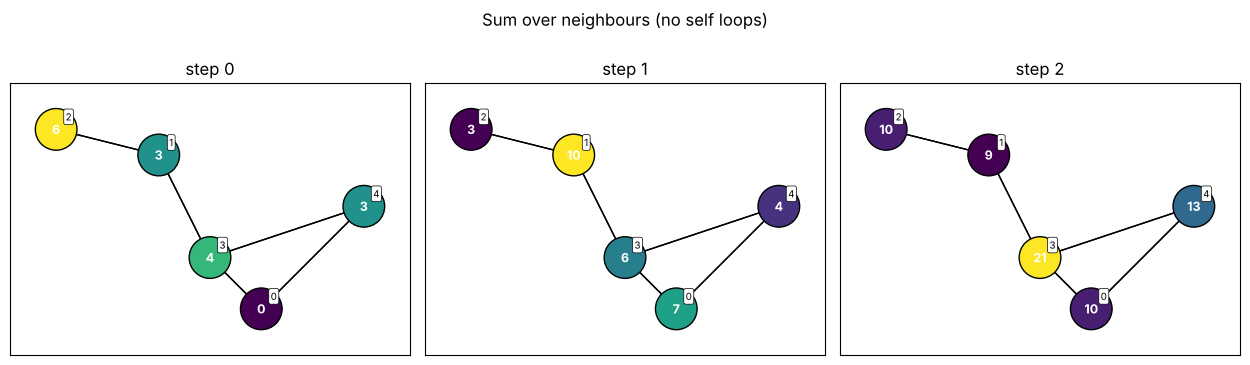

In [2]:
show(iterate(x, edge_index, "add", 2), edge_index, "Sum over neighbours (no self loops)")

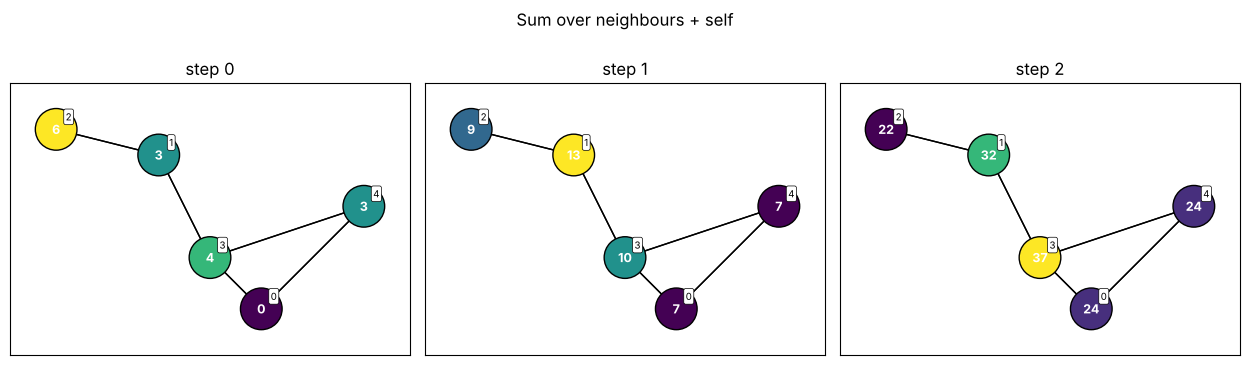

In [3]:
show(iterate(x, edge_index_self, "add", 2), edge_index_self, "Sum over neighbours + self")

## Max aggregation
With self loops, max aggregation spreads the largest value through the graph
one edge per step.

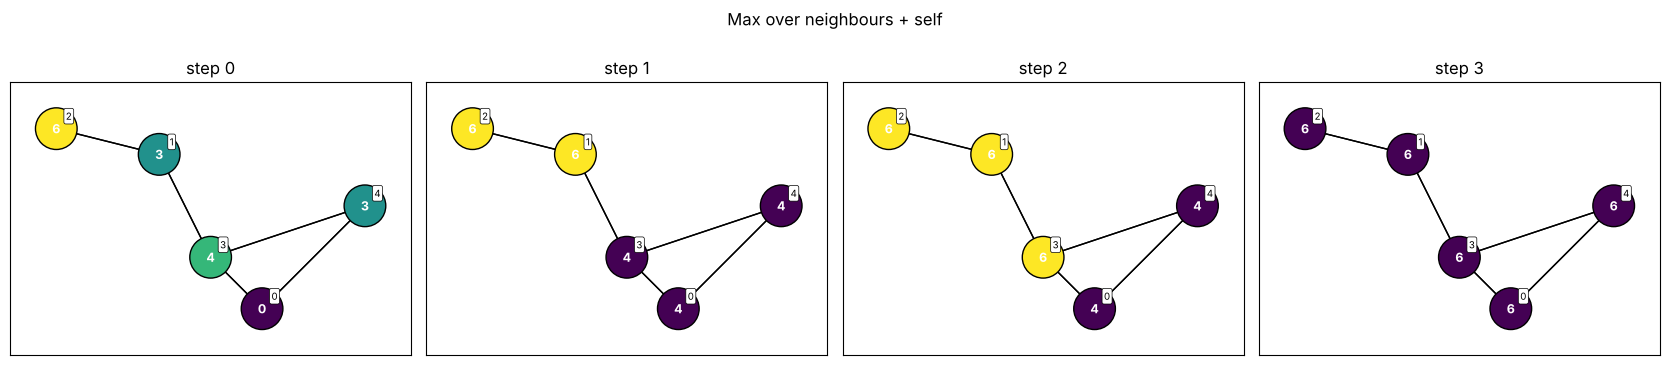

In [4]:
show(iterate(x, edge_index_self, "max", 3), edge_index_self, "Max over neighbours + self")

## A larger graph
35 nodes; node attribute = node index. The highest index spreads outwards
like a wave.

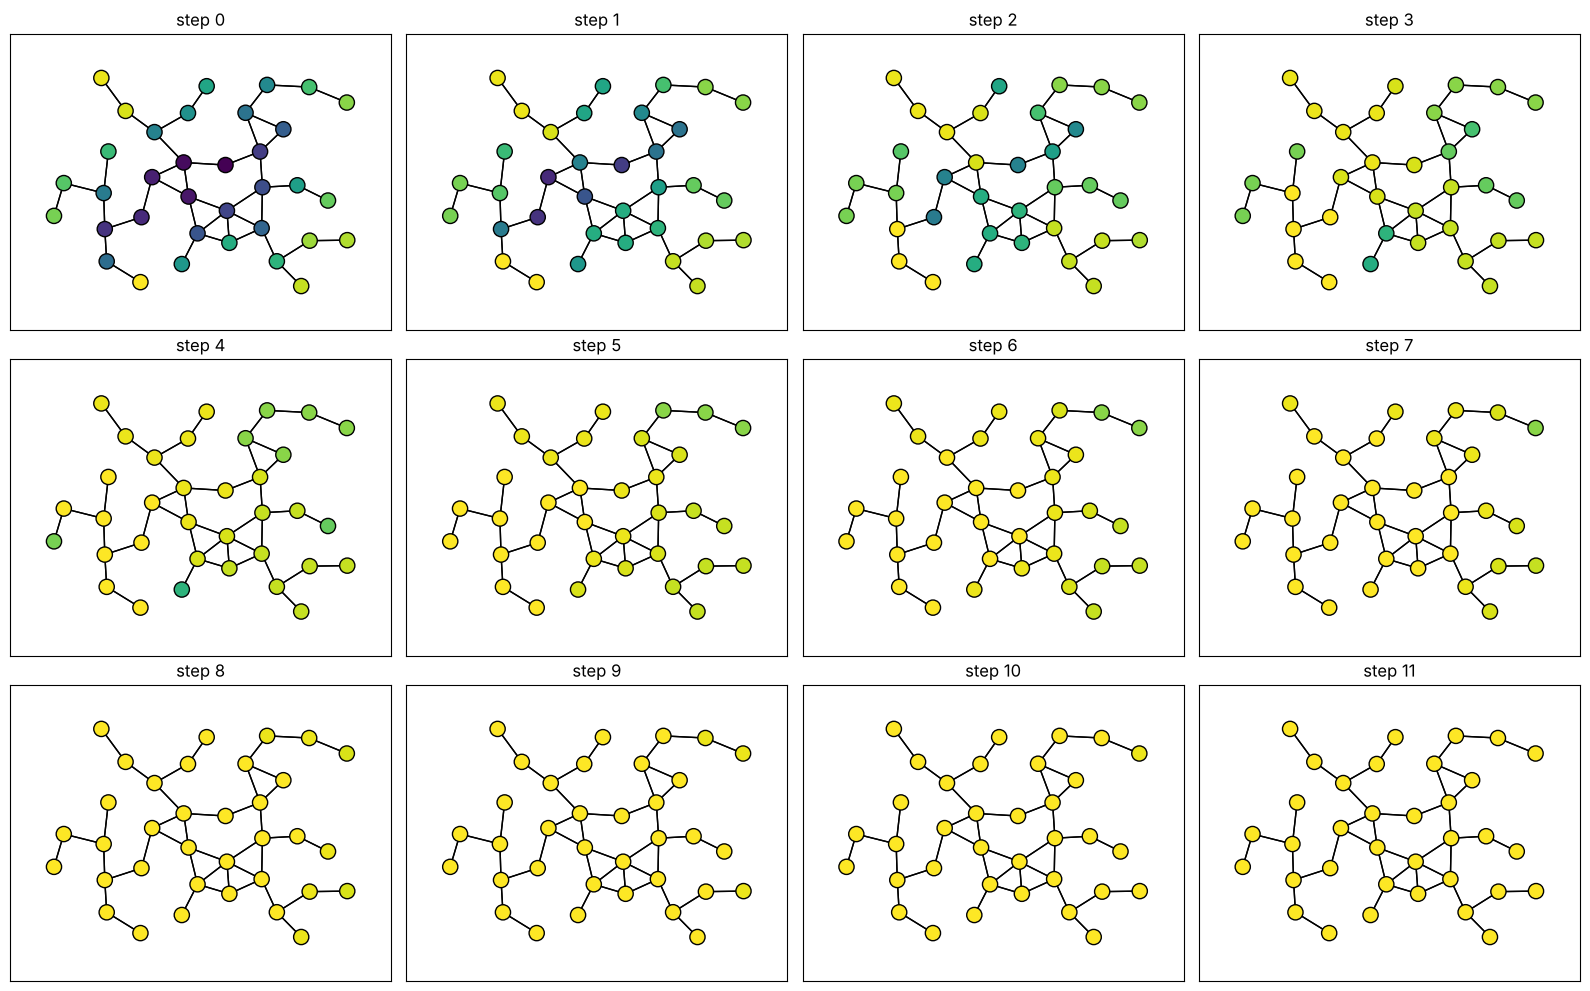

In [5]:
big_pos = random_connected_positions(35, cutoff=2.0, box_size=20)
big_edges = edges_within_cutoff(big_pos, 2.0, self_loops=True)
history = iterate(torch.arange(35, dtype=torch.float32).unsqueeze(1), big_edges, "max", 11)

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for step, (ax, values) in enumerate(zip(axes.flat, history)):
    plot_graph(ax, Data(edge_index=big_edges, pos=big_pos), values=values, size=120,
               vmin=0, vmax=34, fmt="", show_index=False, title=f"step {step}")
fig.tight_layout()
plt.show()